In [3]:
import pandas as pd
#from google.colab import drive


#drive.mount("/content/drive")

### GRÁFICA INTERACTIVA DEL CONTINUO

In [4]:
# @title
#from google.colab import files
ruta_archivo = "/cubos/continuo_IRAS16293.fits"

In [6]:
# @title
import numpy as np
import plotly.graph_objects as go
from astropy.io import fits
from astropy.wcs import WCS
import warnings
from astropy.wcs import FITSFixedWarning
warnings.simplefilter("ignore", FITSFixedWarning)   # silencia los avisos de datfix/obsfix

ruta = "/content/drive/MyDrive/ASTROHACK/cubos/continuo_IRAS16293.fits"
hd = fits.open(ruta)[0]
img = np.squeeze(hd.data).astype(np.float64)        # float64 nativo: corrige el endianness
unidad = str(hd.header.get("BUNIT", ""))
print(img.shape, unidad)

w = WCS(hd.header).celestial
ny, nx = img.shape
yy, xx = np.mgrid[0:ny, 0:nx]
ra, dec = w.pixel_to_world_values(xx, yy)
ra = np.asarray(ra, dtype=np.float64)
dec = np.asarray(dec, dtype=np.float64)

vmin, vmax = np.nanpercentile(img, [1, 99.8])

fig = go.Figure(go.Heatmap(
    z=img, zmin=vmin, zmax=vmax, colorscale="Inferno",
    customdata=np.dstack([ra, dec]),
    hovertemplate=("x=%{x}, y=%{y}<br>%{z:.3e} " + unidad +
                   "<br>RA=%{customdata[0]:.5f}°<br>Dec=%{customdata[1]:.5f}°<extra></extra>"),
    colorbar=dict(title=unidad)
))
fig.update_yaxes(scaleanchor="x")
fig.update_layout(title="Continuo IRAS 16293–2422", xaxis_title="x (píxel)", yaxis_title="y (píxel)")
fig.show()

ModuleNotFoundError: No module named 'plotly'

In [ ]:
hd

# Clustering de las casillas
En este notebook se busca agrupar casillas con gráficas de espectro visualmente similares, el objetivo es que sirva como herramienta para identificar zonas más sencillas de analizar. A diferencia del mapa del continuo


In [ ]:
# @title
import numpy as np
from astropy.io import fits
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt


### 1. Convertir el cubo en una tabla de 4096 filas

In [ ]:
# @title
#CARGAR Y APLANAR
# 1. Cargar y aplanar

with fits.open("/cubos/W1_IRAS16293.fits") as hd:
    cubo = hd[0].data.astype("float64")            # (1918, 64, 64)
n_can, ny, nx = cubo.shape
X = cubo.reshape(n_can, ny * nx).T                  # (4096, 1918)

### 2. Revisar valores vacíos

In [ ]:
# @title
# 2. Revisar vacíos
print("NaN:", np.isnan(X).sum())
valido = ~np.isnan(X).any(axis=1)                   # casillas completas


NaN: 0


### 3. Decidir qué diferencia a los espectros

Sin preprocesar, los grupos tienden a separarse por el brillo del continuo, que distingue A, B y el fondo, y no por sus líneas. Si el interés está en las líneas, conviene restar el nivel de fondo de cada casilla (una lectura posible, no un procedimiento que la Guía imponga; ella pide documentar intervalo y método del fondo, p. 8). Si el interés está en la estructura general del campo, se puede dejar el continuo. Lo más informativo es hacer ambas versiones y comparar.

In [ ]:
# 3. Versión "solo líneas": restar la mediana de cada casilla
Xc = X - np.median(X, axis=1, keepdims=True)

### 4. Reducir dimensiones con PCA

In [ ]:
# @title
# 4. PCA
Xv = Xc[valido]
pca = PCA(n_components=15).fit(Xv)
Z = pca.transform(Xv)
print("Varianza explicada:", pca.explained_variance_ratio_.cumsum()[-1])

Varianza explicada: 0.972930765240062


### Verificar cuál es el mejor valor de K

Con la gráfica de inercia buscamos el valor en el cual

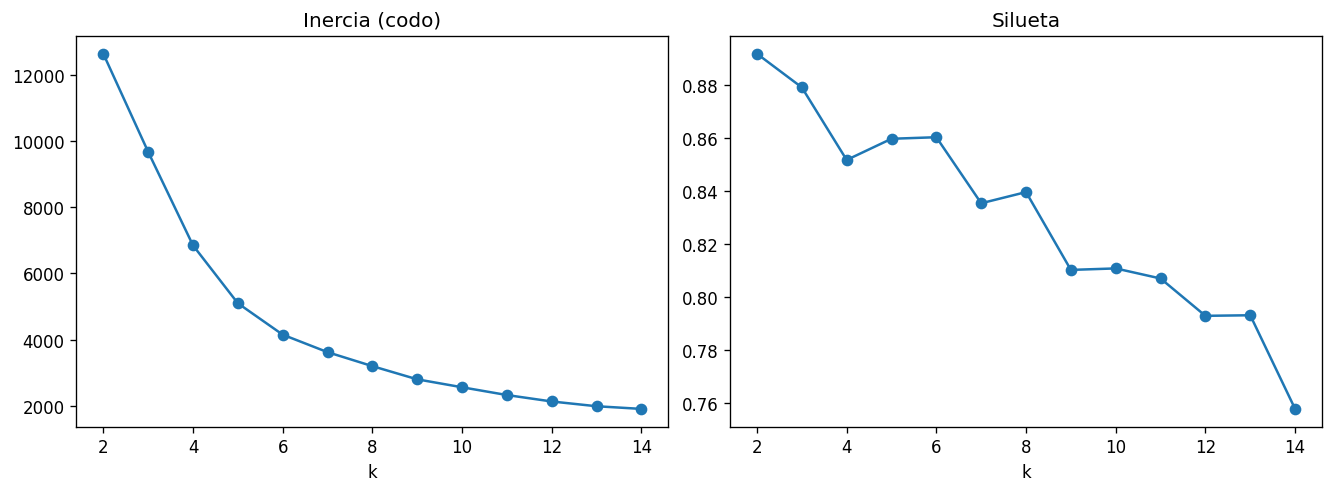

In [ ]:
# @title
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = range(2, 15)
inercia, silueta = [], []
for kk in ks:
    km = KMeans(n_clusters=kk, n_init=10, random_state=0).fit(Z)
    inercia.append(km.inertia_)
    silueta.append(silhouette_score(Z, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4), dpi=120, layout="constrained")
ax[0].plot(ks, inercia, "o-"); ax[0].set(title="Inercia (codo)", xlabel="k")
ax[1].plot(ks, silueta, "o-"); ax[1].set(title="Silueta", xlabel="k")
plt.show()

### 5. Agrupar con K-Means

Se selecciona el valor de k=5 dado que es el punto de inflexión en la gráfica de inercia.

In [ ]:
# @title

k = 5                                               # ajustar según la silueta
lab = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(Z)

In [ ]:
# @title
import numpy as np

# Etiquetas por casilla -> mapa de 64 x 64
# (si 'lab' ya existe de la celda del KMeans, se puede omitir la línea de KMeans)
# from sklearn.cluster import KMeans
# lab = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(Z)

mapa = np.full(ny * nx, -1)                  # -1 = casilla inválida (con NaN)
mapa[valido] = lab
mapa = mapa.reshape(ny, nx)

# Posiciones de las tres extracciones (x = columna, y = fila; Guía, p. 2)
pos = {"B_offset": (54, 46), "B_pico": (50, 48), "A": (18, 11)}

print("Forma del mapa:", mapa.shape, "| grupos:", np.unique(mapa))

Forma del mapa: (64, 64) | grupos: [0 1 2 3 4]


### 6. Visualizar las agrupaciones y las gráficas de cada subgrupo

In [ ]:
# @title
def paleta(k):
    """Devuelve k colores distintos para etiquetas de grupo."""
    if k <= 10:
        base = plt.get_cmap("tab10").colors[:k]
    elif k <= 20:
        t20 = plt.get_cmap("tab20").colors
        base = list(t20[0::2]) + list(t20[1::2])      # primero los 10 saturados, luego los 10 claros
        base = base[:k]
    else:
        base = plt.get_cmap("turbo")(np.linspace(0, 1, k))
    return np.array(base)

#### Mapa de zonas con gráficas de espectro similares

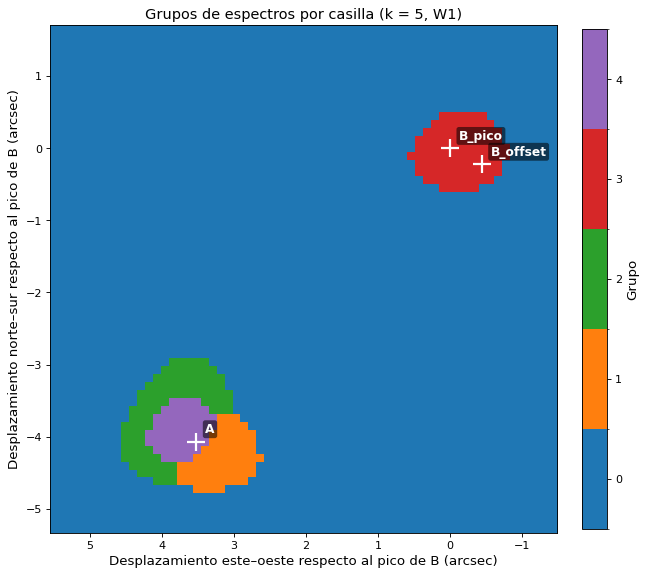

In [ ]:
# @title
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

PIX = 0.11                                   # arcsec por píxel (Guía, p. 2)
x0, y0 = 50, 48                              # píxel de B_pico (x, y), tabla de la Guía, p. 2
colores = paleta(k)
cmap = ListedColormap(colores)
norm = BoundaryNorm(np.arange(-0.5, k + 0.5), cmap.N)

# Desplazamiento en arcsec respecto a B_pico, con este a la izquierda
extent = [(x0 - (-0.5)) * PIX, (x0 - (nx - 0.5)) * PIX,
          (-0.5 - y0) * PIX,   (ny - 0.5 - y0) * PIX]

mapa_m = np.ma.masked_where(mapa < 0, mapa)  # casillas inválidas sin color

fig, ax = plt.subplots(figsize=(8, 7.5), dpi=80, layout="constrained")
im = ax.imshow(mapa_m, origin="lower", cmap=cmap, norm=norm,
               extent=extent, interpolation="nearest")

for nombre, (x, y) in pos.items():
    ex, ny_ = (x0 - x) * PIX, (y - y0) * PIX
    ax.plot(ex, ny_, "+", color="white", ms=16, mew=2)
    ax.annotate(nombre, (ex, ny_), xytext=(8, 8), textcoords="offset points",
                color="white", fontsize=11, weight="bold",
                bbox=dict(boxstyle="round,pad=0.2", fc="black", alpha=0.55, lw=0))

cb = fig.colorbar(im, ax=ax, ticks=np.arange(k), shrink=0.85)
cb.set_label("Grupo", fontsize=12)
ax.set_xlabel("Desplazamiento este–oeste respecto al pico de B (arcsec)", fontsize=12)
ax.set_ylabel("Desplazamiento norte–sur respecto al pico de B (arcsec)", fontsize=12)
ax.set_title(f"Grupos de espectros por casilla (k = {k}, W1)", fontsize=13)
ax.set_aspect("equal")

fig.savefig("mapa_grupos_W1.png", dpi=80)   # archivo de alta resolución
plt.show()

### Gráficas del promedio de intensidad de cada grupo
La zona sombreada corresponde a los percentiles 16 y 84, que es el rango donde se encuentra el 50% de las casillas. La línea principal representa el promedio de la intensidad de la frecuencia en ese canal.

OBSERVACIONES:
- La zona del grupo 3 es la más adecuada para un análisis de este tipo.
- Las señales de A corresponden predominantemente a dos protoestrellas, mientras que B aún no tiene clasificación.

Marco espectral: LSRK | Unidad de señal: Jy/beam
Frecuencia inicial: 348.834448336 GHz | final: 349.302445626 GHz | paso: 0.244130 MHz


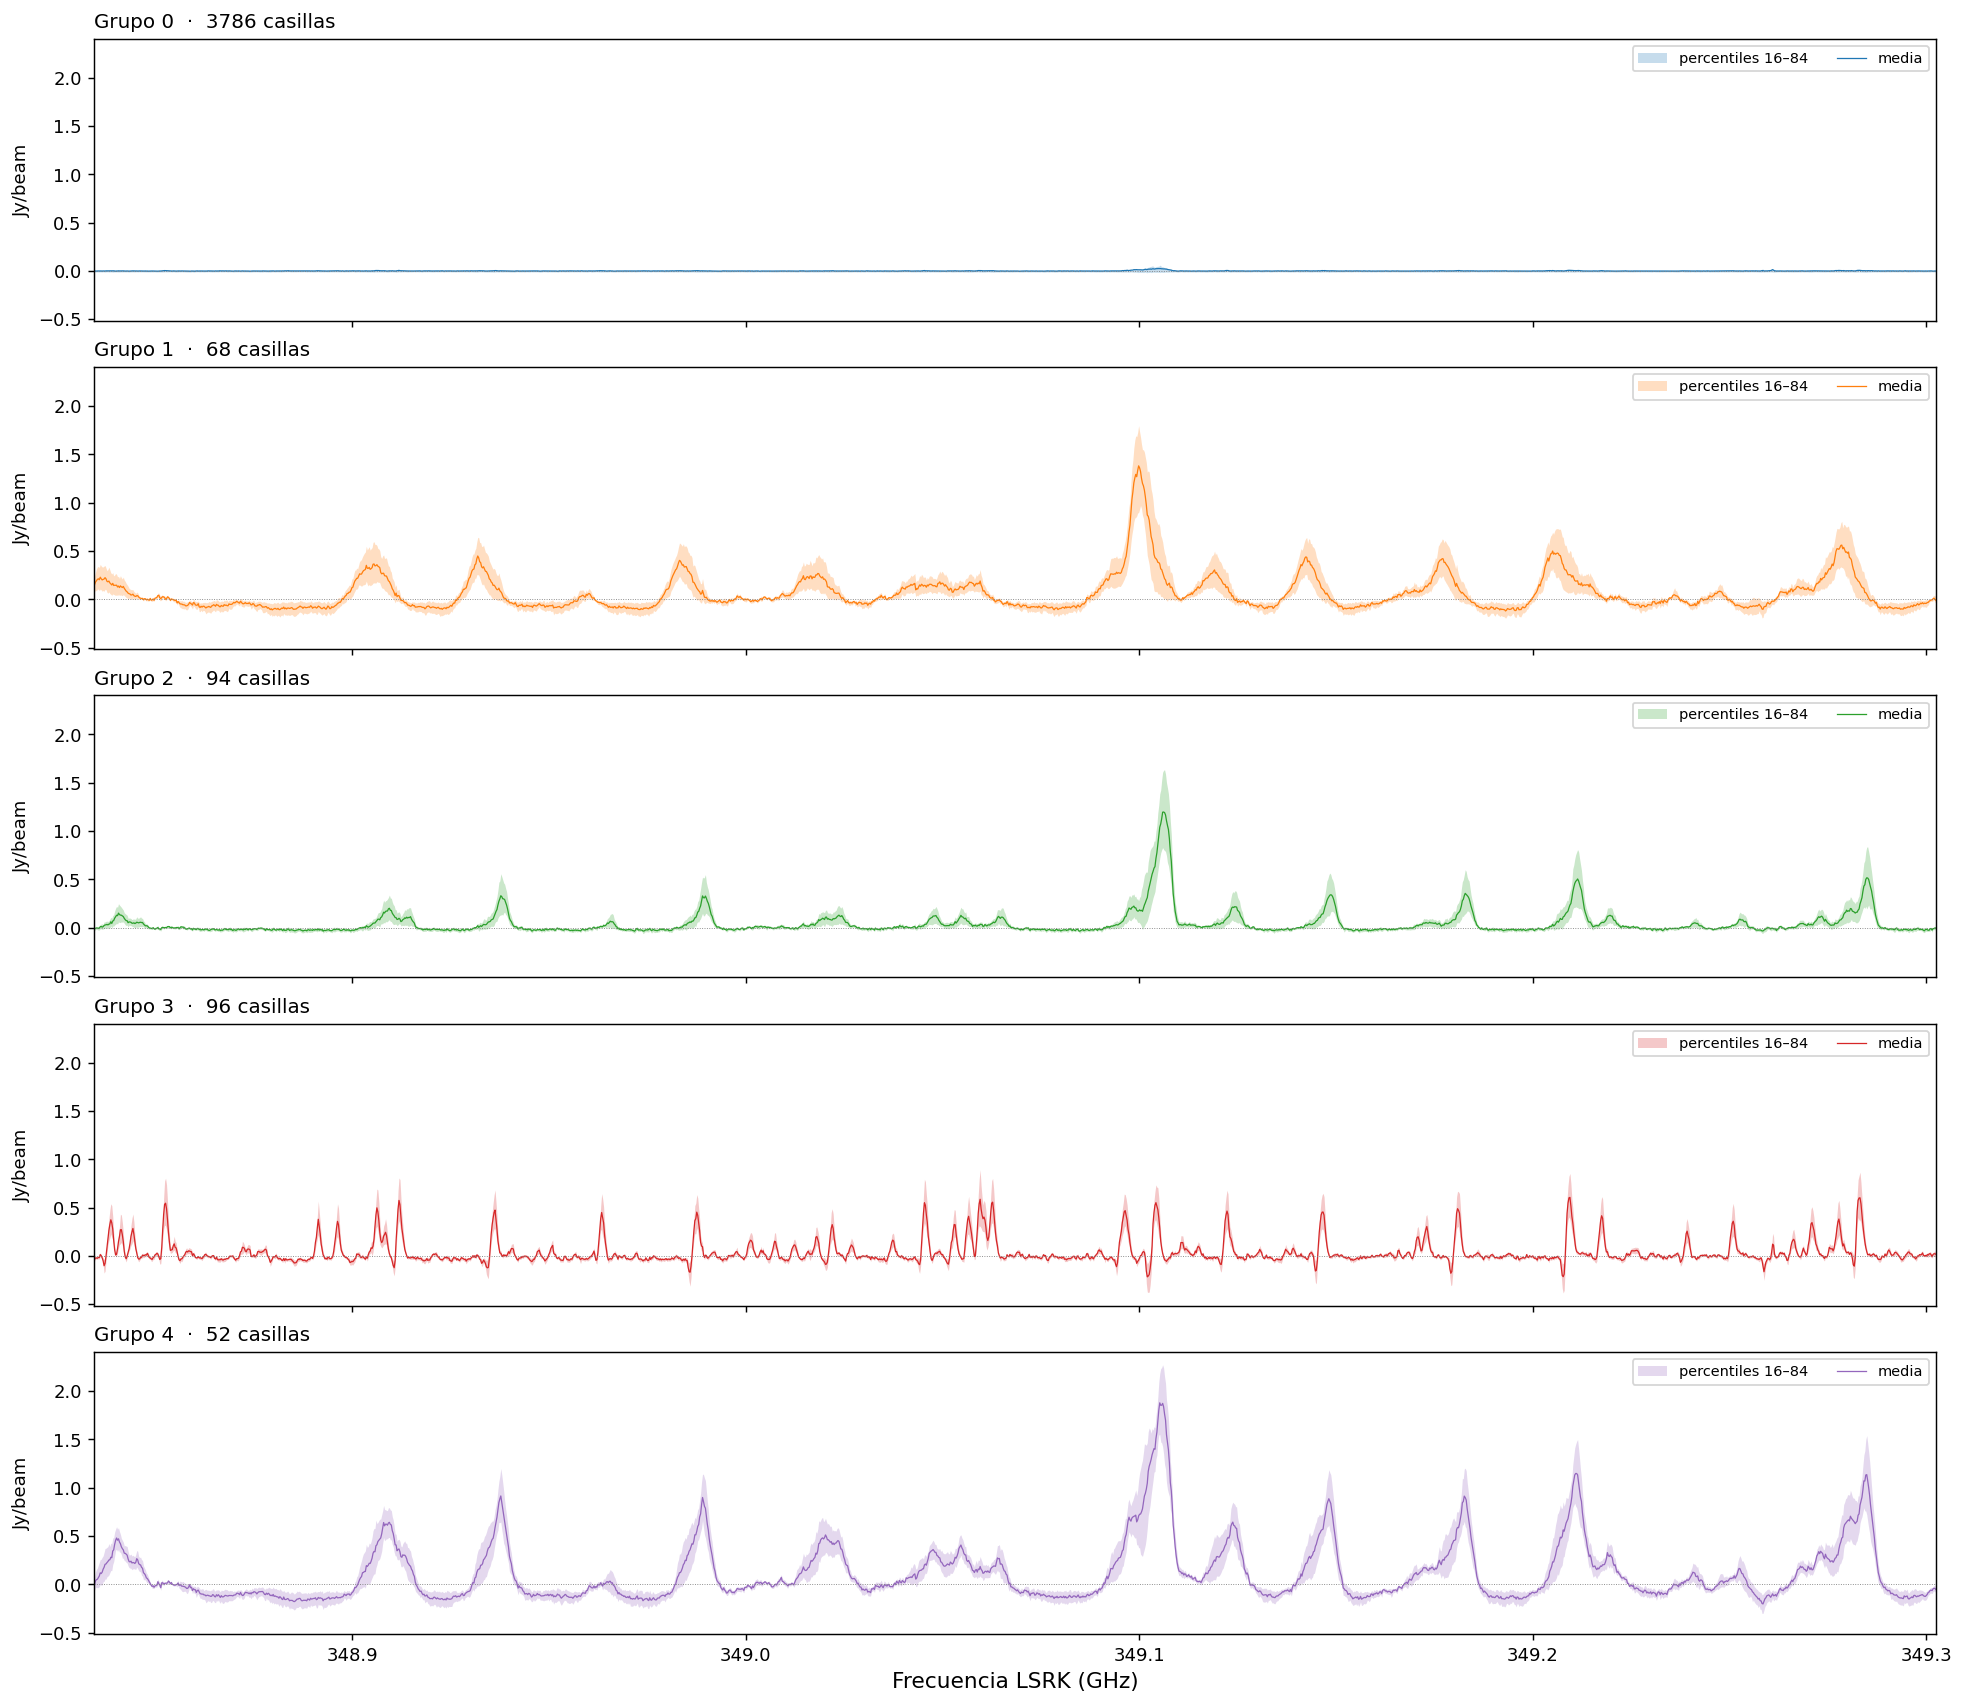

In [ ]:
# @title
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS

# --- Eje de frecuencia desde el encabezado del cubo ---
ruta_cubo = "/cubos/W1_IRAS16293.fits"        # el mismo cubo cargado en la celda del clustering
with fits.open(ruta_cubo, memmap=True) as hd:
    hdr = hd[0].header

print("Marco espectral:", hdr.get("SPECSYS"), "| Unidad de señal:", hdr.get("BUNIT"))

wcs_esp = WCS(hdr).spectral                   # solo el eje de frecuencia
f_hz = wcs_esp.pixel_to_world_values(np.arange(n_can))
f = np.asarray(f_hz, dtype="float64") / 1e9   # Hz -> GHz

# --- Comprobaciones contra los valores de la Guía (p. 3, ventana W1) ---
assert len(f) == n_can, f"El eje de frecuencia tiene {len(f)} valores y el cubo {n_can} canales"
print(f"Frecuencia inicial: {f[0]:.9f} GHz | final: {f[-1]:.9f} GHz | paso: {(f[1]-f[0])*1e3:.6f} MHz")
assert abs(f[0] - 348.834448336) < 1e-6 and abs(f[-1] - 349.302445626) < 1e-6, \
    "Las frecuencias no coinciden con W1 de la Guía; revisa que el cubo cargado sea W1"

# --- Gráfica ---
colores = paleta(k)
etiquetas = mapa.ravel()

fig, axes = plt.subplots(k, 1, figsize=(15, 2.6 * k), dpi=130,
                         sharex=True, sharey=True, layout="constrained")
axes = np.atleast_1d(axes)

for g, ax in enumerate(axes):
    S = Xc[etiquetas == g]                    # espectros de ese grupo (con fondo restado)
    media = S.mean(axis=0)
    p16, p84 = np.percentile(S, [16, 84], axis=0)
    ax.fill_between(f, p16, p84, color=colores[g], alpha=0.25, lw=0,
                    label="percentiles 16–84")
    ax.plot(f, media, color=colores[g], lw=0.7, label="media")
    ax.axhline(0, color="gray", lw=0.5, ls=":")
    ax.set_ylabel("Jy/beam")
    ax.set_title(f"Grupo {g}  ·  {len(S)} casillas", loc="left", fontsize=11)
    ax.legend(loc="upper right", fontsize=8, ncol=2)

axes[-1].set_xlabel("Frecuencia LSRK (GHz)", fontsize=12)
axes[-1].set_xlim(f.min(), f.max())           # para ampliar: set_xlim(349.00, 349.05)

fig.savefig("espectros_grupos_W1.png", dpi=300)
plt.show()

## VERIFICAR SI EL AGRUPAMIENTO OFRECE MÁS INFORMACIÓN QUE EL MAPA DE CONTINUO

### Paso 1: Continuo en la cuadrícula del cubo
Identificar que la sección del continuo analizada corresponda con la cuadrícula de 64 por 64

In [ ]:
# @title
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS

with fits.open("/cubos/W1_IRAS16293.fits") as hd:
    wcs_cubo = WCS(hd[0].header).celestial
with fits.open("/cubos/continuo_IRAS16293.fits") as hd:
    img = hd[0].data.squeeze().astype("float64")
    wcs_cont = WCS(hd[0].header).celestial

yy, xx = np.mgrid[0:ny, 0:nx]
ra, dec = wcs_cubo.pixel_to_world_values(xx, yy)
xk, yk = wcs_cont.world_to_pixel_values(ra, dec)
xk, yk = np.round(xk).astype(int), np.round(yk).astype(int)
assert (xk.min() >= 0) and (yk.min() >= 0) and (xk.max() < img.shape[1]) and (yk.max() < img.shape[0]), \
    "Algún píxel del cubo cae fuera del mapa de continuo"

cont = img[yk, xk]                                   # (64, 64)
print("Continuo en B_pico:", cont[48, 50], "| máximo del campo:", np.nanmax(cont))

Continuo en B_pico: 2.51345157623291 | máximo del campo: 2.51345157623291


### Paso 2: Cuánto se parecen los grupos a un mapa de continuo

In [ ]:
# @title
import numpy as np

c_all = cont.ravel()[valido]          # continuo de las casillas válidas del cubo
ok = np.isfinite(c_all)                 # de esas, las que tienen continuo finito
c = c_all[ok]
lab_ok = lab[ok]

print("casillas válidas:", int(valido.sum()), "| con continuo finito:", int(ok.sum()))
print("longitudes -> c:", len(c), "| lab_ok:", len(lab_ok))

casillas válidas: 4096 | con continuo finito: 4096
longitudes -> c: 4096 | lab_ok: 4096


In [ ]:
# @title
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

df = pd.DataFrame({"grupo": lab_ok, "cont": c})

# 1) Cómo se distribuye el continuo dentro de cada grupo
print(df.groupby("grupo")["cont"].agg(["count", "min", "median", "max"]).round(3))

# 2) eta²: fracción de la varianza del continuo explicada por el grupo (0 a 1)
media_g = df.groupby("grupo")["cont"].transform("mean")
eta2 = 1 - ((df.cont - media_g) ** 2).sum() / ((df.cont - df.cont.mean()) ** 2).sum()
print("eta²:", round(eta2, 3))

# 3) Partición "solo continuo" con los MISMOS tamaños que los grupos de KMeans
orden_g = df.groupby("grupo")["cont"].mean().sort_values().index.to_numpy()   # de menos a más brillante
tam = df.groupby("grupo").size().loc[orden_g].to_numpy()
rango = np.argsort(np.argsort(c))                    # 0 = casilla menos brillante
bloque = np.searchsorted(np.cumsum(tam), rango, side="right")
lab_cont_igual = orden_g[bloque]

print("NMI:", round(normalized_mutual_info_score(lab_ok, lab_cont_igual), 3))
print("ARI:", round(adjusted_rand_score(lab_ok, lab_cont_igual), 3))

# 4) En qué grupo cae cada posición de extracción
for nombre, (x, y) in pos.items():
    print(nombre, "-> grupo", mapa[y, x])

       count    min  median    max
grupo                             
0       3786 -0.035   0.012  0.952
1         68  0.310   0.636  1.359
2         94  0.096   0.340  0.720
3         96  0.362   1.160  2.513
4         52  0.460   0.944  1.452
eta²: 0.747
NMI: 0.576
ARI: 0.833
B_offset -> grupo 3
B_pico -> grupo 3
A -> grupo 4


### Paso 3: Qué parte de los espectros explicar el continuo

Fracción de varianza espectral explicada por el continuo: 0.466


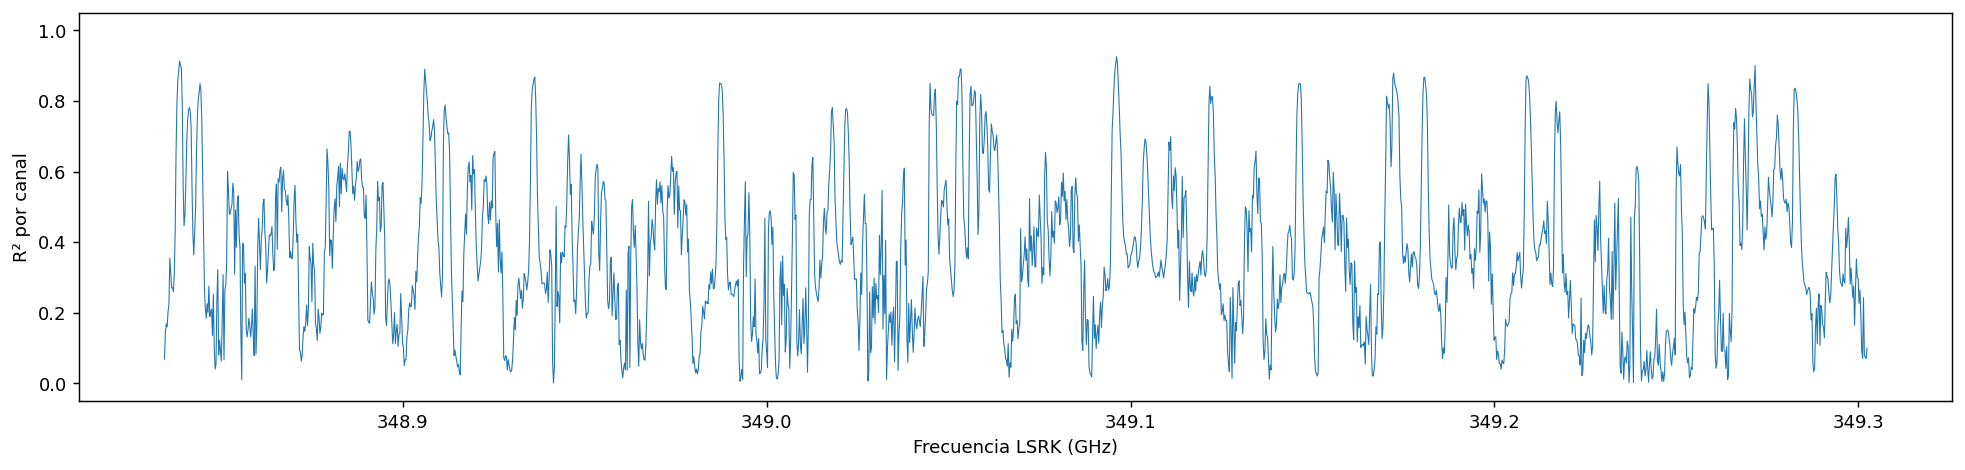

In [ ]:
# @title
import matplotlib.pyplot as plt

Xv = Xc[valido][ok]                                  # (casillas válidas, 1918)
z = (c - c.mean()) / c.std()
V = np.vander(z, 4)                                  # columnas: z³, z², z, 1
coef, *_ = np.linalg.lstsq(V, Xv, rcond=None)
res = Xv - V @ coef                                  # residuo por casilla y canal

r2_global = 1 - res.var(axis=0).sum() / Xv.var(axis=0).sum()
r2_canal = 1 - res.var(axis=0) / Xv.var(axis=0)
print("Fracción de varianza espectral explicada por el continuo:", round(r2_global, 3))

fig, ax = plt.subplots(figsize=(15, 3.5), dpi=130, layout="constrained")
ax.plot(f, r2_canal, lw=0.6)
ax.set(xlabel="Frecuencia LSRK (GHz)", ylabel="R² por canal", ylim=(-0.05, 1.05))
plt.show()

##